[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PIML_PEQ_2026/blob/main/JupyterNotebooks/PCML_Module3_UQ_Membrane.ipynb)

# Module 3 Tutorial: Estimation and Uncertainty Quantification for a Membrane Separator
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

Uncertainty quantification (UQ) of physics-informed models is key for reliability and robustness testing, experimental
design, and advanced tasks such as real-time optimization and control. In this tutorial, we use the physics-constrained NN
(PCNN) of Module 2 for the membrane separator, and we will:

1. Estimate the model parameters with **maximum likelihood** (MLE) and with **Bayesian (MAP)** estimation.
2. Quantify parameter and prediction uncertainty with the **Laplace approximation** (this requires the Hessian).
3. Quantify uncertainty with **variational inference** (VI), solved with a gradient-based method (Adam).
4. Use **Gaussian processes** (inherently probabilistic) and propagate their uncertainty through a function of the
   outputs using **sampling** and **linearization** (needed for Bayesian optimization).

### Connection to the slides (Module 3)

| Slides | Code |
|---|---|
| Model $\mathbf{y}=\mathbf{m}(\theta,\mathbf{X})+\mathbf{e}$ | `model(theta, X)` |
| Negative log-likelihood $-\log f(\mathbf{y}\mid\theta)$ | `neg_log_likelihood(theta)` |
| Negative log-prior $-\log f(\theta)$ | `neg_log_prior(theta)` |
| Hessian $\mathcal{H}(\hat\theta)$ | `torch.autograd.functional.hessian` |
| Variational density $q(\theta\mid\lambda)$, ELBO | `mu`, `rho`, `neg_elbo` |
| GP predictive mean and std $\mu(x),\sigma(x)$ | `gp.predict(..., return_std=True)` |

### Before the workshop

    conda create -n pcml -c conda-forge python=3.11 numpy matplotlib scikit-learn jupyterlab ipykernel
    conda activate pcml
    python -m pip install torch
    jupyter lab

On Google Colab, all required packages are already installed. The whole notebook runs in about one minute.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

SEED = 26
torch.set_default_dtype(torch.float64)

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have an external LaTeX installation
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
})

### 1. Membrane separator and data (same as Module 2)

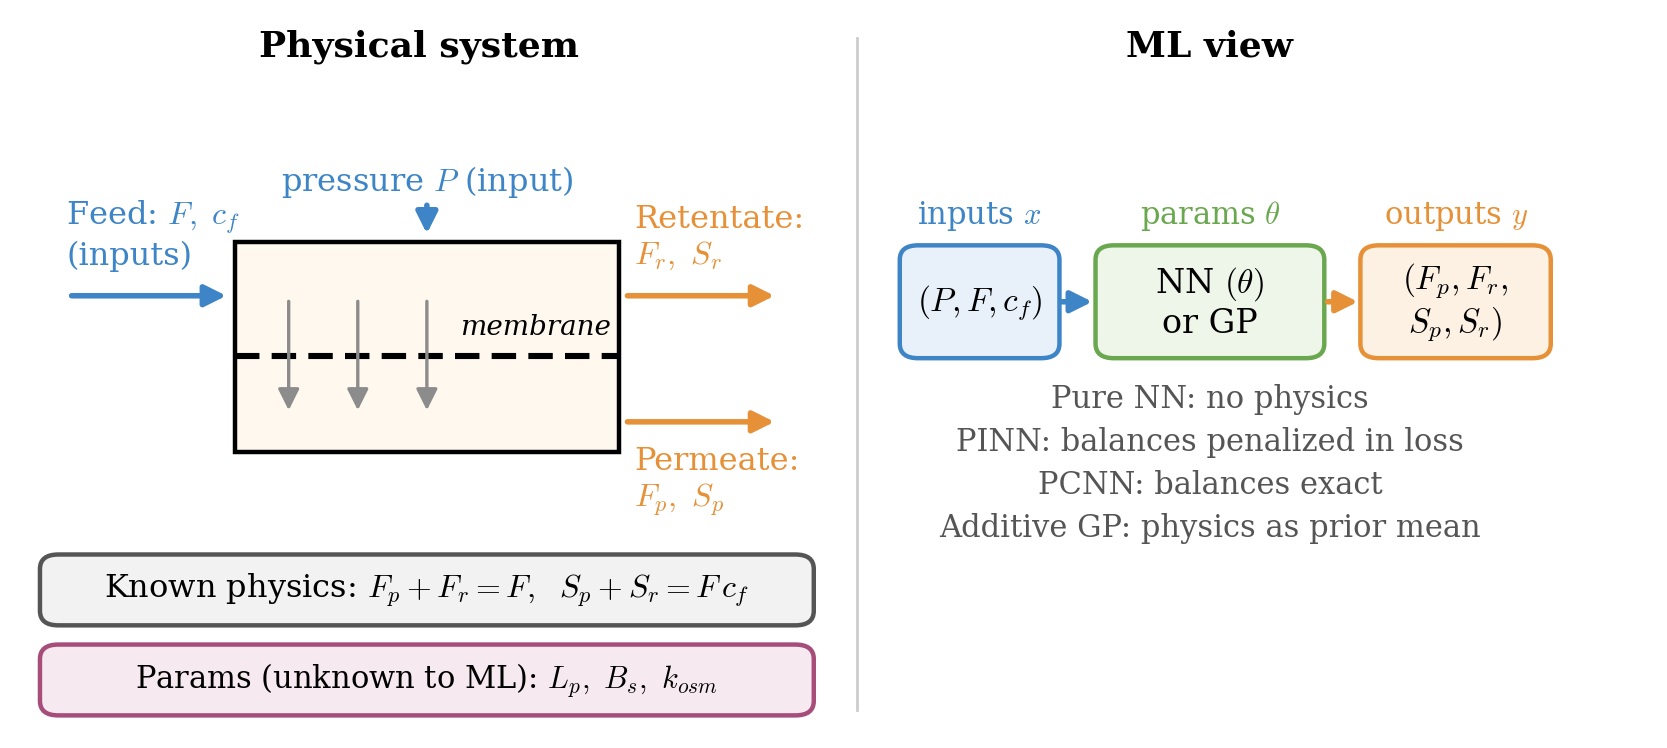

Inputs: pressure $P\in[5,15]$ bar, feed flow $F\in[50,150]$ kg/h, and feed concentration $c_f\in[0.01,0.03]$.
Outputs: permeate and retentate flows $F_p,F_r$ and solute flows $S_p,S_r$ (kg/h). We have only $N=10$ noisy experiments.
The data are generated with a solution-diffusion model that the ML model does not know.

In [2]:
Lp_true, B_s, k_osm = 9.0, 6.0, 120.0


def membrane(X):
    # true model (used only to generate data); returns Fp, Fr, Sp, Sr
    P, F, cf = X[:, 0], X[:, 1], X[:, 2]
    Jw = Lp_true*np.maximum(P - k_osm*cf, 0.0)
    Fp = 0.9*(1 - np.exp(-Jw/F))*F
    Sp = Fp*cf*B_s/(B_s + Fp)
    return np.column_stack([Fp, F - Fp, Sp, F*cf - Sp])


lo, hi = np.array([5.0, 50.0, 0.01]), np.array([15.0, 150.0, 0.03])


def sample_inputs(n, rng):
    return lo + (hi - lo)*rng.uniform(size=(n, 3))


sigma = np.array([1.5, 1.5, 0.005, 0.03])          # measurement noise of Fp, Fr, Sp, Sr

rng = np.random.default_rng(SEED)
X_train = sample_inputs(10, rng)
Y_train = membrane(X_train) + rng.normal(size=(10, 4))*sigma

X_test = sample_inputs(1000, np.random.default_rng(999))
Y_test = membrane(X_test)

# slice of the input space for plots: vary P, keep F = 100 kg/h and cf = 0.02
P_slice = np.linspace(5, 15, 101)
X_slice = np.column_stack([P_slice, 100.0*np.ones(101), 0.02*np.ones(101)])
Y_slice = membrane(X_slice)

### 2. The PCNN as a function of a parameter vector $\theta$

We write the PCNN of Module 2 explicitly as a model $\mathbf{m}(\theta,\mathbf{x})$, where $\theta\in\mathbb{R}^{p}$ collects all
weights and biases of the NN (one hidden layer with 8 tanh neurons):

$$h=\tanh(W_1\tilde x+b_1),\qquad (z_1,z_2)=W_2h+b_2,\qquad \theta=(W_1,b_1,W_2,b_2),\quad p=24+8+16+2=50$$

The NN predicts the recovery $R=F_p/F$ and the solute split $s=S_p/(Fc_f)$, and the mass balances give the retentate:

$$\hat F_p=R\,F,\qquad \hat S_p=s\,F\,c_f,\qquad \hat F_r=F-\hat F_p,\qquad \hat S_r=F\,c_f-\hat S_p$$

In [3]:
p = 50


def unpack(theta):
    W1 = theta[0:24].reshape(8, 3)
    b1 = theta[24:32]
    W2 = theta[32:48].reshape(2, 8)
    b2 = theta[48:50]
    return W1, b1, W2, b2


def model(theta, X):
    # PCNN prediction m(theta, X) of (Fp, Fr, Sp, Sr)
    W1, b1, W2, b2 = unpack(theta)
    Xt = torch.tensor(X)
    x_scaled = (Xt - torch.tensor([10.0, 100.0, 0.02]))/torch.tensor([5.0, 50.0, 0.01])
    z = torch.tanh(x_scaled @ W1.T + b1) @ W2.T + b2
    F, cf = Xt[:, 1], Xt[:, 2]
    R = 0.45 + 0.25*z[:, 0]                           # recovery
    s = 0.07 + 0.04*z[:, 1]                           # solute split
    Fp, Sp = R*F, s*F*cf
    return torch.stack([Fp, F - Fp, Sp, F*cf - Sp], dim=1)


Y_data, sig = torch.tensor(Y_train), torch.tensor(sigma)


def neg_log_likelihood(theta):
    # -log f(y | theta) for Gaussian noise (up to a constant)
    return 0.5*torch.sum(((model(theta, X_train) - Y_data)/sig)**2)


alpha = 10.0                                          # prior precision: theta ~ N(0, I/alpha)


def neg_log_prior(theta):
    # -log f(theta) for a Gaussian prior (up to a constant)
    return 0.5*alpha*torch.sum(theta**2)


def errors(theta):
    # test RMSE of Fp (kg/h) and of retentate purity cr (g/kg)
    with torch.no_grad():
        Y = model(theta, X_test).numpy()
    e_fp = np.sqrt(np.mean((Y[:, 0] - Y_test[:, 0])**2))
    e_cr = 1e3*np.sqrt(np.mean((Y[:, 3]/Y[:, 1] - Y_test[:, 3]/Y_test[:, 1])**2))
    return e_fp, e_cr

### 3. Maximum likelihood vs. Bayesian (MAP) estimation

**MLE** finds the parameters that make the data most likely:
$\hat\theta_{MLE}\in\mathrm{argmin}_\theta\; -\log f(\mathbf{y}|\theta)$.

**Bayesian (MAP) estimation** maximizes the posterior $f(\theta|\mathbf{y})\propto f(\mathbf{y}|\theta)f(\theta)$:
$\hat\theta_{MAP}\in\mathrm{argmin}_\theta\; -\log f(\mathbf{y}|\theta)-\log f(\theta)$. With a Gaussian prior
$\theta\sim\mathcal{N}(0,\alpha^{-1}I)$, the prior term is the regularizer $\frac{\alpha}{2}\|\theta\|^2$.

Both problems are nonconvex (the NN is nonlinear). We solve each from three random initializations with Adam.

Estimation time: 7.0 s

Method  Init  RMSE Fp (kg/h)  RMSE cr (g/kg)   min eig(H)
MLE       0            5.13            3.66       -0.009
MLE       1            3.54            2.81       -0.178
MLE       2            4.11            2.55       -5.430
MAP       0            1.89            1.55        0.682
MAP       1            1.89            1.55        0.663
MAP       2            1.89            1.55        0.745


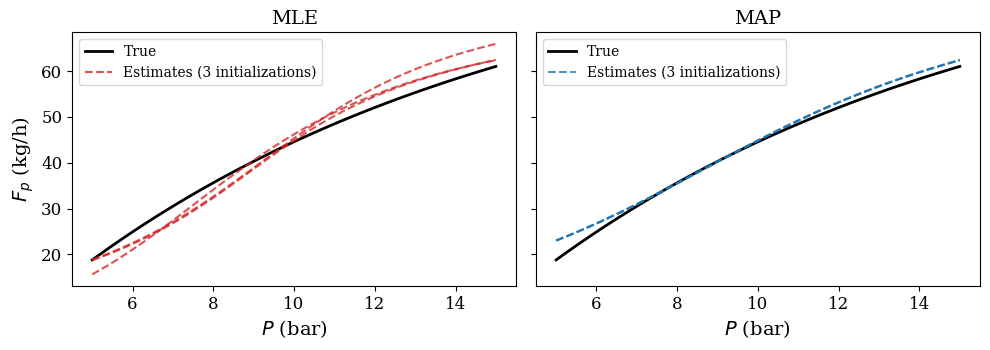

In [4]:
def estimate(objective, seed, iters=6000):
    # minimize objective(theta) with Adam from a random initialization
    torch.manual_seed(seed)
    theta = (0.3*torch.randn(p)).requires_grad_(True)
    optimizer = torch.optim.Adam([theta], lr=0.01)
    for it in range(iters):
        optimizer.zero_grad()
        loss = objective(theta)
        loss.backward()
        optimizer.step()
    return theta.detach()


neg_log_posterior = lambda theta: neg_log_likelihood(theta) + neg_log_prior(theta)

t0 = time.perf_counter()
results = {}
for lab, objective in [("MLE", neg_log_likelihood), ("MAP", neg_log_posterior)]:
    results[lab] = [estimate(objective, seed) for seed in [26, 1, 2]]
print(f"Estimation time: {time.perf_counter() - t0:.1f} s\n")

print(f"{'Method':5s} {'Init':>5s} {'RMSE Fp (kg/h)':>15s} {'RMSE cr (g/kg)':>15s} {'min eig(H)':>12s}")
for lab, objective in [("MLE", neg_log_likelihood), ("MAP", neg_log_posterior)]:
    for k, theta in enumerate(results[lab]):
        H = torch.autograd.functional.hessian(objective, theta)
        e_fp, e_cr = errors(theta)
        print(f"{lab:5s} {k:5d} {e_fp:15.2f} {e_cr:15.2f} {torch.linalg.eigvalsh(H)[0].item():12.3f}")

theta_map = results["MAP"][0]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, lab, col in zip(axes, ["MLE", "MAP"], ["tab:red", "tab:blue"]):
    ax.plot(P_slice, Y_slice[:, 0], "k-", lw=2, label="True")
    for k, theta in enumerate(results[lab]):
        with torch.no_grad():
            ax.plot(P_slice, model(theta, X_slice)[:, 0].numpy(), "--", color=col, alpha=0.8,
                    label="Estimates (3 initializations)" if k == 0 else None)
    ax.set(xlabel="$P$ (bar)", title=lab)
    ax.legend(loc="upper left")
axes[0].set_ylabel("$F_p$ (kg/h)")
plt.tight_layout()
plt.show()

**Observations**

- The MLE estimates depend on the initialization: with 50 parameters and few data, the likelihood has many (nearly)
  equivalent minima. The Hessian at the MLE has eigenvalues close to zero (or negative): the parameters are not well
  defined by the data.
- The prior regularizes the problem: MAP estimates are consistent across initializations, more accurate, and the Hessian
  is positive definite.

### 4. Laplace approximation

The Laplace approximation fits a Gaussian to the posterior around the MAP estimate:

$$f(\theta|\mathbf{y})\approx\mathcal{N}\left(\hat\theta,\ \mathcal{H}(\hat\theta)^{-1}\right),\qquad
\mathcal{H}(\hat\theta)=\nabla^2_\theta\left[-\log f(\mathbf{y}|\theta)-\log f(\theta)\right]_{\theta=\hat\theta}$$

The **covariance of the parameters is the inverse of the Hessian**. To propagate it to a prediction $\hat y(x)=m(\hat\theta,x)$,
we linearize the model around $\hat\theta$:

$$\mathbb{V}[\hat y(x)]\approx \nabla_\theta m(\hat\theta,x)^T\,\mathcal{H}(\hat\theta)^{-1}\,\nabla_\theta m(\hat\theta,x)$$

For our small NN the Hessian is a $50\times 50$ matrix that PyTorch computes with automatic differentiation. For a NN with
$10^6$ parameters it would have $10^{12}$ entries; computing, storing, and inverting it is impossible.

In [5]:
t0 = time.perf_counter()
H = torch.autograd.functional.hessian(neg_log_posterior, theta_map)
Cov_theta = torch.linalg.inv(H)                       # parameter covariance
print(f"Hessian: {H.shape[0]} x {H.shape[1]}, computed in {time.perf_counter() - t0:.2f} s")
print("Parameter standard deviations: min = {:.3f}, max = {:.3f}".format(
    torch.sqrt(torch.diag(Cov_theta)).min().item(), torch.sqrt(torch.diag(Cov_theta)).max().item()))


def laplace_predict(X, output=0):
    # mean and std of one output using the linearized Laplace approximation
    J = torch.autograd.functional.jacobian(lambda th: model(th, X)[:, output], theta_map)   # N x p
    var = torch.einsum("ij,jk,ik->i", J, Cov_theta, J)
    with torch.no_grad():
        mean = model(theta_map, X)[:, output]
    return mean.numpy(), torch.sqrt(var).numpy()


mean_lap, sd_lap = laplace_predict(X_test)
coverage_lap = np.mean(np.abs(Y_test[:, 0] - mean_lap) <= 1.96*sd_lap)
print(f"Laplace: RMSE Fp = {np.sqrt(np.mean((mean_lap - Y_test[:, 0])**2)):.2f} kg/h, "
      f"95% interval contains true Fp for {100*coverage_lap:.0f}% of test inputs")

Hessian: 50 x 50, computed in 0.02 s
Parameter standard deviations: min = 0.115, max = 0.792
Laplace: RMSE Fp = 1.89 kg/h, 95% interval contains true Fp for 78% of test inputs


### 5. Variational inference (VI)

VI approximates the posterior with a simple density $q(\theta|\lambda)$ whose parameters $\lambda$ are found by optimization.
We use a Gaussian with independent components (mean-field):

$$q(\theta|\lambda)=\prod_{i=1}^p\mathcal{N}(\theta_i\,|\,\mu_i,\sigma_i^2),\qquad \lambda=(\mu,\rho),\qquad \sigma_i=e^{\rho_i}$$

We choose $\lambda$ to minimize the Kullback-Leibler divergence $\mathrm{KL}\left(q(\theta|\lambda)\,\|\,f(\theta|\mathbf{y})\right)$,
which is equivalent to maximizing the **evidence lower bound** (ELBO):

$$\mathrm{ELBO}(\lambda)=\mathbb{E}_{q}\left[\log f(\mathbf{y}|\theta)\right]-\mathrm{KL}\left(q(\theta|\lambda)\,\|\,f(\theta)\right)$$

The first term rewards fitting the data; the second keeps $q$ close to the prior (for Gaussian $q$ and prior it has a
closed form). The expectation is estimated by Monte Carlo with the **reparameterization trick**:

$$\theta^{(s)}=\mu+\sigma\odot\varepsilon^{(s)},\qquad \varepsilon^{(s)}\sim\mathcal{N}(0,I),\qquad
\mathbb{E}_q\left[\log f(\mathbf{y}|\theta)\right]\approx\frac{1}{S}\sum_{s=1}^S\log f(\mathbf{y}|\theta^{(s)})$$

Because $\theta^{(s)}$ is a differentiable function of $\lambda$, PyTorch computes $\nabla_\lambda\mathrm{ELBO}$ by back propagation,
and we maximize the ELBO with **Adam** (a stochastic gradient method; the Monte Carlo samples make the gradient noisy).
VI has $2p$ parameters and **does not need the Hessian**.

VI training time: 8.6 s


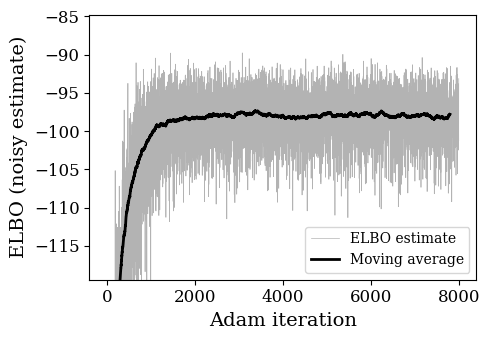

In [6]:
def kl_to_prior(mu, rho):
    # KL( N(mu, sigma^2) || N(0, 1/alpha) ), summed over parameters
    var = torch.exp(2*rho)
    return 0.5*torch.sum(alpha*(var + mu**2) - 1 - 2*rho - np.log(alpha))


def neg_elbo(mu, rho, S=8):
    eps = torch.randn(S, p)
    theta_samples = mu + torch.exp(rho)*eps               # reparameterization trick
    expected_nll = torch.stack([neg_log_likelihood(th) for th in theta_samples]).mean()
    return expected_nll + kl_to_prior(mu, rho)


torch.manual_seed(SEED)
mu = theta_map.clone().requires_grad_(True)               # start the means at the MAP estimate
rho = torch.full((p,), -2.0, requires_grad=True)          # small initial standard deviations
optimizer = torch.optim.Adam([mu, rho], lr=0.005)
history = []
t0 = time.perf_counter()
for it in range(8000):
    optimizer.zero_grad()
    loss = neg_elbo(mu, rho)
    loss.backward()
    optimizer.step()
    history.append(-loss.item())
print(f"VI training time: {time.perf_counter() - t0:.1f} s")

plt.figure(figsize=(5, 3.5))
plt.plot(history, color="0.7", lw=0.5, label="ELBO estimate")
plt.plot(np.convolve(history, np.ones(200)/200, mode="valid"), "k-", lw=2, label="Moving average")
plt.ylim(np.percentile(history, 5), max(history) + 5)
plt.legend(loc="lower right")
plt.xlabel("Adam iteration")
plt.ylabel("ELBO (noisy estimate)")
plt.tight_layout()
plt.show()

In [7]:
def vi_predict(X, output=0, S=500):
    # sample parameters from q and propagate them through the model
    with torch.no_grad():
        theta_samples = mu + torch.exp(rho)*torch.randn(S, p)
        Y = torch.stack([model(th, X)[:, output] for th in theta_samples]).numpy()
    return Y


Y_vi = vi_predict(X_test)
lo_vi, hi_vi = np.quantile(Y_vi, [0.025, 0.975], axis=0)
coverage_vi = np.mean((Y_test[:, 0] >= lo_vi) & (Y_test[:, 0] <= hi_vi))
print(f"VI: RMSE Fp = {np.sqrt(np.mean((Y_vi.mean(0) - Y_test[:, 0])**2)):.2f} kg/h, "
      f"95% interval contains true Fp for {100*coverage_vi:.0f}% of test inputs")

VI: RMSE Fp = 2.07 kg/h, 95% interval contains true Fp for 85% of test inputs


### 6. Compare Laplace and VI predictions

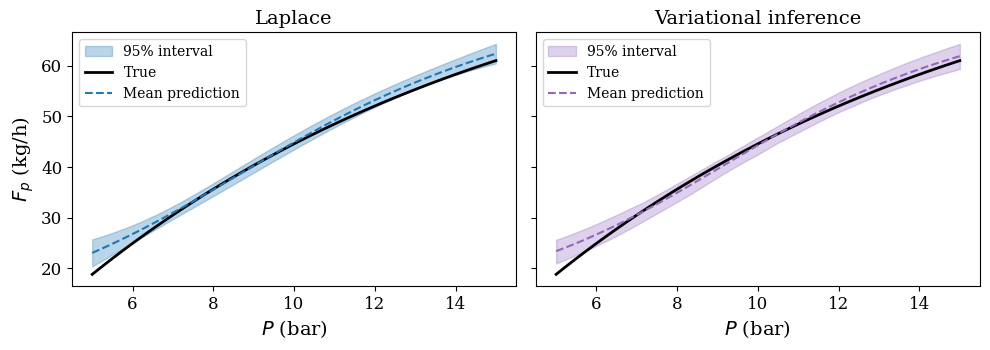

Method     Avg 95% width (kg/h)   Coverage
Laplace                     4.5        78%
VI                          5.0        85%


In [8]:
mean_l, sd_l = laplace_predict(X_slice)
Y_v = vi_predict(X_slice)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (lab, m, lo_b, hi_b, col) in zip(axes, [
        ("Laplace", mean_l, mean_l - 1.96*sd_l, mean_l + 1.96*sd_l, "tab:blue"),
        ("Variational inference", Y_v.mean(0), *np.quantile(Y_v, [0.025, 0.975], axis=0), "tab:purple")]):
    ax.fill_between(P_slice, lo_b, hi_b, color=col, alpha=0.3, label="95% interval")
    ax.plot(P_slice, Y_slice[:, 0], "k-", lw=2, label="True")
    ax.plot(P_slice, m, "--", color=col, label="Mean prediction")
    ax.set(xlabel="$P$ (bar)", title=lab)
    ax.legend(loc="upper left")
axes[0].set_ylabel("$F_p$ (kg/h)")
plt.tight_layout()
plt.show()

print(f"{'Method':8s} {'Avg 95% width (kg/h)':>22s} {'Coverage':>10s}")
print(f"{'Laplace':8s} {np.mean(2*1.96*sd_lap):22.1f} {100*coverage_lap:9.0f}%")
print(f"{'VI':8s} {np.mean(hi_vi - lo_vi):22.1f} {100*coverage_vi:9.0f}%")

**Observations**

- Laplace and VI give similar mean predictions and similar uncertainty bands for this small model.
- Both bands contain the true response for most (but not all) test inputs; both approximations tend to be somewhat
  overconfident (mean-field VI ignores correlations between parameters; Laplace is a local approximation).
- Laplace requires the Hessian ($p\times p$); VI only requires gradients and scales to large models.

### 7. When the Laplace approximation breaks: strong nonlinearity

The Laplace approximation only uses the **local curvature at the MAP estimate**. When the model is strongly nonlinear in
the parameters, the posterior can be far from Gaussian (e.g., skewed), and the curvature at the mode misrepresents it.
VI fits its Gaussian by optimizing the ELBO over the whole posterior and is more robust.

To see this clearly, we use a model with a single parameter that enters cubically (a vanishing-gradient nonlinearity,
similar to what happens with saturated neurons):

$$y=\theta^3x+\epsilon,\qquad \epsilon\sim\mathcal{N}(0,0.05^2),\qquad \theta\sim\mathcal{N}(0,1)$$

with 10 observations for $x\in[0.1,1]$ and true value $\theta=0.15$. With one parameter, we can compute the **exact posterior**
on a grid and use it as the reference.

In [9]:
rng_c = np.random.default_rng(1)
x_c = np.linspace(0.1, 1.0, 10)
sig_c, alpha_c = 0.05, 1.0
y_c = 0.15**3*x_c + rng_c.normal(size=10)*sig_c
Xc, Yc = torch.tensor(x_c), torch.tensor(y_c)


def neg_log_post_c(th):
    return 0.5*torch.sum((Yc - th**3*Xc)**2)/sig_c**2 + 0.5*alpha_c*th**2


# exact posterior on a grid
grid = np.linspace(-1.0, 1.0, 4001)
with torch.no_grad():
    log_post = -np.array([neg_log_post_c(torch.tensor(t)).item() for t in grid])
post = np.exp(log_post - log_post.max())
post /= np.trapz(post, grid)
cdf = np.cumsum(post)*(grid[1] - grid[0])

# Laplace: MAP estimate and Hessian
th = torch.tensor(0.5, requires_grad=True)
opt = torch.optim.Adam([th], lr=0.01)
for it in range(5000):
    opt.zero_grad()
    loss = neg_log_post_c(th)
    loss.backward()
    opt.step()
th_map_c = th.detach()
sd_lap_c = 1/np.sqrt(torch.autograd.functional.hessian(neg_log_post_c, th_map_c).item())

# VI: Gaussian q(theta | mu, rho), maximize ELBO with Adam
torch.manual_seed(SEED)
mu_c = torch.tensor(0.5, requires_grad=True)
rho_c = torch.tensor(-2.0, requires_grad=True)
opt = torch.optim.Adam([mu_c, rho_c], lr=0.01)
for it in range(5000):
    opt.zero_grad()
    sd = torch.exp(rho_c)
    th_s = mu_c + sd*torch.randn(16)                  # reparameterization
    exp_nll = torch.stack([0.5*torch.sum((Yc - t**3*Xc)**2)/sig_c**2 for t in th_s]).mean()
    kl = 0.5*(alpha_c*(sd**2 + mu_c**2) - 1 - 2*rho_c - np.log(alpha_c))
    (exp_nll + kl).backward()
    opt.step()
mu_vi_c, sd_vi_c = mu_c.item(), torch.exp(rho_c).item()

mean_exact = np.trapz(grid*post, grid)
sd_exact = np.sqrt(np.trapz((grid - mean_exact)**2*post, grid))
print(f"Exact posterior: mean = {mean_exact:.3f}, std = {sd_exact:.3f}")
print(f"Laplace:         mean = {th_map_c.item():.3f}, std = {sd_lap_c:.3f}")
print(f"VI:              mean = {mu_vi_c:.3f}, std = {sd_vi_c:.3f}")

Exact posterior: mean = 0.073, std = 0.188
Laplace:         mean = 0.263, std = 0.123
VI:              mean = 0.061, std = 0.156


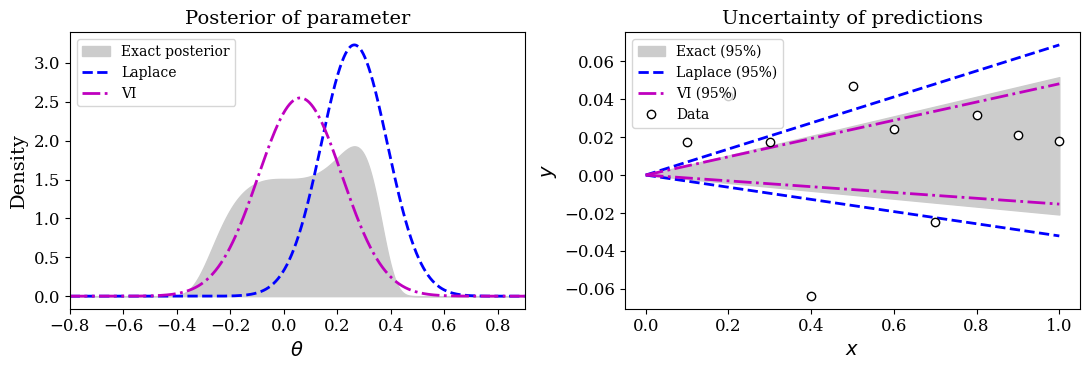

95% band of y at x=1: exact [-0.021, 0.052], Laplace [-0.032, 0.069], VI [-0.015, 0.048]


In [10]:
gauss = lambda t, m, s: np.exp(-0.5*((t - m)/s)**2)/(s*np.sqrt(2*np.pi))
x_plot = np.linspace(0, 1, 101)

# predictive 95% bands for y(x) = theta^3 x
q_lo, q_hi = np.interp([0.025, 0.975], cdf, grid)
exact_lo, exact_hi = q_lo**3*x_plot, q_hi**3*x_plot
m_l = th_map_c.item()
lap_mean = m_l**3*x_plot
lap_sd = 3*m_l**2*sd_lap_c*x_plot                        # linearization
th_vi = mu_vi_c + sd_vi_c*np.random.default_rng(SEED).normal(size=20000)
vi_lo, vi_hi = np.quantile(th_vi**3, [0.025, 0.975])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.fill_between(grid, post, color="0.8", label="Exact posterior")
ax.plot(grid, gauss(grid, m_l, sd_lap_c), "b--", lw=2, label="Laplace")
ax.plot(grid, gauss(grid, mu_vi_c, sd_vi_c), "m-.", lw=2, label="VI")
ax.set(xlim=(-0.8, 0.9), xlabel=r"$\theta$", ylabel="Density", title="Posterior of parameter")
ax.legend(loc="upper left")
ax = axes[1]
ax.fill_between(x_plot, exact_lo, exact_hi, color="0.8", label="Exact (95%)")
ax.plot(x_plot, lap_mean - 1.96*lap_sd, "b--", lw=2, label="Laplace (95%)")
ax.plot(x_plot, lap_mean + 1.96*lap_sd, "b--", lw=2)
ax.plot(x_plot, vi_lo*x_plot, "m-.", lw=2, label="VI (95%)")
ax.plot(x_plot, vi_hi*x_plot, "m-.", lw=2)
ax.plot(x_c, y_c, "ko", mfc="w", label="Data")
ax.set(xlabel="$x$", ylabel="$y$", title="Uncertainty of predictions")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"95% band of y at x=1: exact [{exact_lo[-1]:.3f}, {exact_hi[-1]:.3f}], "
      f"Laplace [{lap_mean[-1] - 1.96*lap_sd[-1]:.3f}, {lap_mean[-1] + 1.96*lap_sd[-1]:.3f}], "
      f"VI [{vi_lo:.3f}, {vi_hi:.3f}]")

**Observations**

- The exact posterior is far from Gaussian (flat and skewed): the cubic model makes values of $\theta$ near zero almost
  indistinguishable ($\theta^3$ is nearly flat there).
- The Laplace approximation is centered at the mode and uses the local curvature there; it misplaces the posterior and its
  prediction band is shifted and too wide.
- VI optimizes over the whole posterior and stays consistent with the exact posterior, both for the parameter and for
  the predictions.
- NNs and hybrid models are strongly nonlinear in their parameters; this is one more reason to use VI for UQ.

### 8. Gaussian processes: propagating uncertainty through functions

GP models are **inherently probabilistic**: the prediction at a new input is Gaussian,
$y(x)\sim\mathcal{N}(\mu(x),\sigma^2(x))$, so predictive uncertainty comes directly (no Hessian or VI needed).

In applications we often care about a **function of the outputs**. For the membrane, the retentate purity
$c_r=f(F_r,S_r)=S_r/F_r$ is a nonlinear function of two GP predictions. To quantify the uncertainty of $f$ we must
**propagate** the GP uncertainty through $f$. This is exactly what Bayesian optimization needs when the performance
is a function of GP models (Module 4). We compare two approaches:

**Sampling (Monte Carlo):** draw $y_s\sim\mathcal{N}(\mu(x),\sigma^2(x))$, evaluate $f(y_s)$, and compute
$\hat m_f(x)=\frac{1}{S}\sum_s f(y_s)$ and $\hat\sigma_f^2(x)=\frac{1}{S-1}\sum_s\left(f(y_s)-\hat m_f(x)\right)^2$.

**Linearization:** approximate $f(y)\approx f(\mu)+\nabla_y f(\mu)^T(y-\mu)$; since linear transformations of Gaussians are
Gaussian, $m_f(x)=f(\mu(x))$ and $\sigma_f^2(x)=\nabla_y f^T\,\Sigma_y(x)\,\nabla_y f$. For $c_r=S_r/F_r$,
$\nabla_y f=(-S_r/F_r^2,\ 1/F_r)$.

We train one GP for $F_r$ and one for $S_r$ with the same 10 experiments.

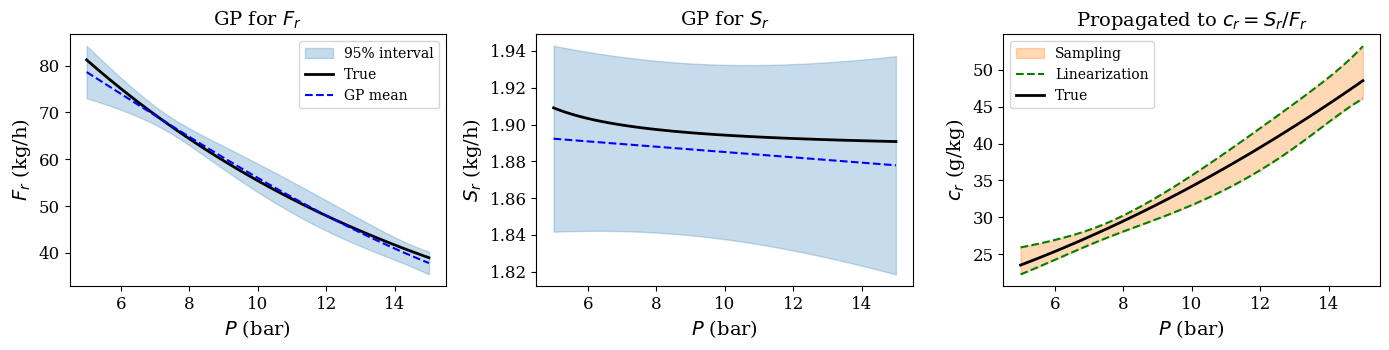

Sampling (2000 samples): 2.7 ms; linearization: 0.06 ms
Max difference in mean: 0.144 g/kg; max difference in std: 0.079 g/kg


In [11]:
def fit_gp(X, y, noise_sd):
    kernel = ConstantKernel(1.0, (1e-3, 1e3))*RBF(np.ones(3), (1e-2, 1e2))
    gp = GaussianProcessRegressor(kernel=kernel, alpha=(noise_sd/y.std())**2, normalize_y=True,
                                  n_restarts_optimizer=5, random_state=SEED)
    return gp.fit((X - np.array([10.0, 100.0, 0.02]))/np.array([5.0, 50.0, 0.01]), y)


def gp_predict(gp, X):
    return gp.predict((X - np.array([10.0, 100.0, 0.02]))/np.array([5.0, 50.0, 0.01]), return_std=True)


gp_Fr = fit_gp(X_train, Y_train[:, 1], sigma[1])
gp_Sr = fit_gp(X_train, Y_train[:, 3], sigma[3])

mu_Fr, sd_Fr = gp_predict(gp_Fr, X_slice)
mu_Sr, sd_Sr = gp_predict(gp_Sr, X_slice)
cr_true = 1e3*Y_slice[:, 3]/Y_slice[:, 1]                 # g/kg

# sampling
t0 = time.perf_counter()
S = 2000
rng_s = np.random.default_rng(SEED)
Fr_s = mu_Fr + sd_Fr*rng_s.normal(size=(S, len(P_slice)))
Sr_s = mu_Sr + sd_Sr*rng_s.normal(size=(S, len(P_slice)))
cr_s = 1e3*Sr_s/Fr_s
m_samp, sd_samp = cr_s.mean(axis=0), cr_s.std(axis=0, ddof=1)
t_samp = time.perf_counter() - t0

# linearization
t0 = time.perf_counter()
m_lin = 1e3*mu_Sr/mu_Fr
grad_Fr, grad_Sr = -1e3*mu_Sr/mu_Fr**2, 1e3/mu_Fr          # gradient of f = Sr/Fr
sd_lin = np.sqrt(grad_Fr**2*sd_Fr**2 + grad_Sr**2*sd_Sr**2)
t_lin = time.perf_counter() - t0

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, (lab, mu_, sd_, true, unit) in zip(axes[:2], [("GP for $F_r$", mu_Fr, sd_Fr, Y_slice[:, 1], "$F_r$ (kg/h)"),
                                                      ("GP for $S_r$", mu_Sr, sd_Sr, Y_slice[:, 3], "$S_r$ (kg/h)")]):
    ax.fill_between(P_slice, mu_ - 1.96*sd_, mu_ + 1.96*sd_, color="tab:blue", alpha=0.25, label="95% interval")
    ax.plot(P_slice, true, "k-", lw=2, label="True")
    ax.plot(P_slice, mu_, "b--", label="GP mean")
    ax.set(xlabel="$P$ (bar)", ylabel=unit, title=lab)
axes[0].legend(loc="upper right")
ax = axes[2]
ax.fill_between(P_slice, m_samp - 1.96*sd_samp, m_samp + 1.96*sd_samp, color="tab:orange", alpha=0.3, label="Sampling")
ax.plot(P_slice, m_lin - 1.96*sd_lin, "g--", label="Linearization")
ax.plot(P_slice, m_lin + 1.96*sd_lin, "g--")
ax.plot(P_slice, cr_true, "k-", lw=2, label="True")
ax.set(xlabel="$P$ (bar)", ylabel="$c_r$ (g/kg)", title="Propagated to $c_r=S_r/F_r$")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Sampling ({S} samples): {1e3*t_samp:.1f} ms; linearization: {1e3*t_lin:.2f} ms")
print(f"Max difference in mean: {np.abs(m_samp - m_lin).max():.3f} g/kg; "
      f"max difference in std: {np.abs(sd_samp - sd_lin).max():.3f} g/kg")

**Observations**

- The GPs directly provide the uncertainty of $F_r$ and $S_r$.
- Sampling and linearization give almost the same uncertainty for the purity $c_r$; linearization requires a single
  evaluation of $f$ and its gradient, while sampling requires thousands of evaluations at every input.
- In Bayesian optimization, this calculation is repeated at every candidate input in every iteration; this is why
  cheap propagation (e.g., adaptive linearization in BOIS) matters.

### 9. Key takeaways

- Estimating parameters of physics-informed ML models follows the same logic as classical estimation (MLE, Bayesian), but
  the problems are larger and highly nonlinear; priors regularize them.
- The Laplace approximation quantifies uncertainty using the Hessian (the inverse covariance of the parameters), which
  may be impossible to obtain for complex models.
- Variational inference casts UQ as an optimization problem that is solved with gradient-based methods (Adam); it is
  more robust than Laplace when the model is strongly nonlinear.
- GPs are inherently probabilistic; their uncertainty can be propagated through functions by sampling or by linearization.

### 10. Optional exercises

1. **Prior strength.** Repeat the study with $\alpha=1$ and $\alpha=100$. How do the estimates and the bands change?
2. **More data.** Use 40 experiments. Do the bands shrink?
3. **Samples.** Change the number of Monte Carlo samples in the ELBO ($S=1$ and $S=32$). How does the ELBO history change?
4. **Pure NN.** Repeat the UQ for a pure NN (no mass balances, four outputs). How do the uncertainty bands of $F_r$ compare?
5. **Propagation.** Propagate the GP uncertainty through the solute recovery $S_r/(Fc_f)$ with sampling and linearization.

### References

- Zavala, V. M. (2025). *Statistics for Chemical Engineers*. Cambridge University Press.
- Kingma, D. P., and Welling, M. (2014). Auto-encoding variational Bayes. ICLR. https://arxiv.org/abs/1312.6114
- Blei, D. M., Kucukelbir, A., and McAuliffe, J. D. (2017). Variational inference: A review for statisticians.
  *Journal of the American Statistical Association*, 112(518), 859–877.
- González, L. D., and Zavala, V. M. (2025). On the implementation of a Bayesian optimization framework for interconnected
  systems. arXiv:2501.00967.
- Thompson, J., Connors, B. M., Zavala, V. M., and Venturelli, O. S. (2026). Physics-constrained neural ordinary differential
  equation models to discover and predict microbial community dynamics. *PNAS*, 123(13), e2517661123.